In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
def func(x, a, b, c):
    return a * np.exp(-b * x) + c

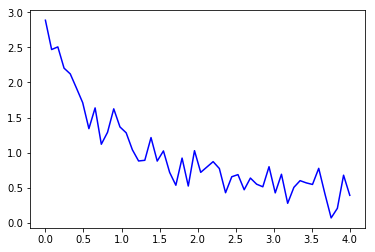

In [3]:
xdata = np.linspace(0, 4, 50)
y = func(xdata, 2.5, 1.3, 0.5)
y_noise = 0.2 * np.random.normal(size=xdata.size)
ydata = y + y_noise
plt.plot(xdata, ydata, 'b-', label='data')
plt.show()

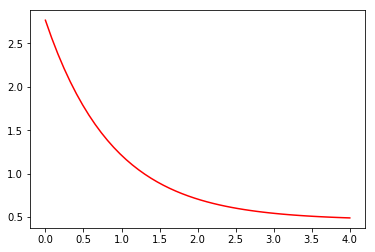

In [4]:
popt, pcov = curve_fit(func, xdata, ydata)
plt.plot(xdata, func(xdata, *popt), 'r-', label='fit')
plt.show()


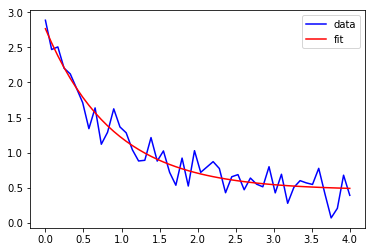

In [5]:
p1, = plt.plot(xdata, ydata, 'b-', label='data')
p2, = plt.plot(xdata, func(xdata, *popt), 'r-', label='fit')
plt.legend(handles=[p1,p2])
plt.show()

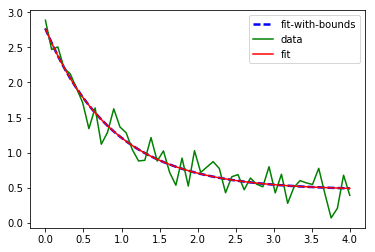

In [6]:
popt, pcov = curve_fit(func, xdata, ydata, bounds=(0, [3., 2., 1.]))
p1, = plt.plot(xdata, func(xdata, *popt), 'b--',lw=2.5,label='fit-with-bounds')
p2, = plt.plot(xdata, ydata, 'g-', label='data')
p3, = plt.plot(xdata, func(xdata, *popt), 'r-', label='fit')
plt.legend(handles=[p1,p2,p3])
plt.show()

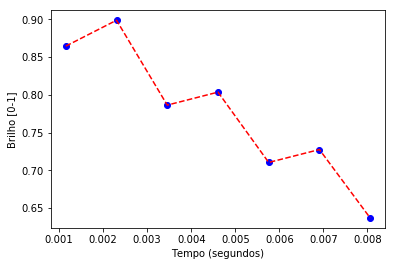

In [7]:
fatPercent = 0.05

t = [0.0011515,  \
     0.0011515*2,\
     0.0011515*3,\
     0.0011515*4,\
     0.0011515*5,\
     0.0011515*6,\
     0.0011515*7]

rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water

t2star = [0.030,\
          0.040,\
          0.051,\
          0.052,\
          0.062,\
          0.083,\
          0.023]

Fppmn = [5.3,\
         4.2,\
         2.75,\
         2.1,\
         1.3,\
         0.9,\
         4.7]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
t2star = np.array(t2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal) #descobrir o erro no np.absolute
plt.plot(t, Sfinal,'bo')
plt.plot(t, Sfinal,'r--')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()

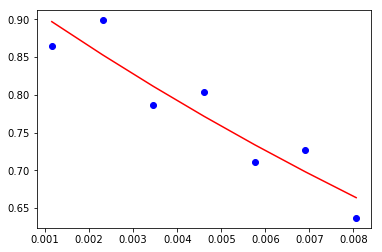

In [8]:
def func_V1(x, a, b, c, d):
    return a*np.exp(b*x) + c*np.exp(d*t)

popt, pcov = curve_fit(lambda t,a,b,c,d: a*np.exp(b*t) + c*np.exp(d*t),  t,  Sfinal)
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(t, func_V1(t,*popt), 'r-', label='fit')
plt.show()

In [9]:
popt

array([  0.34224309, -43.57246315,   0.60073766, -43.55738195])

In [10]:
pcov

array([[ -1.77127108e+12,   5.00246105e+10,   1.77127104e+12,
         -7.29481724e+10],
       [  5.01330625e+10,   8.77326242e+11,  -5.01331269e+10,
         -4.98491948e+11],
       [  1.77127104e+12,  -5.00246748e+10,  -1.77127101e+12,
          7.29482082e+10],
       [ -7.30099498e+10,  -4.98494670e+11,   7.30099856e+10,
          2.82124523e+11]])

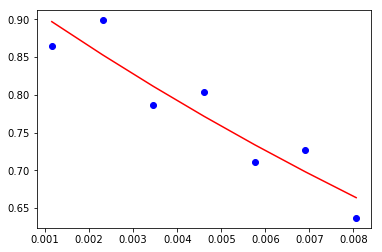

In [11]:
def func_V2(x, a, b, d):
    return np.abs(a*np.exp(b*x)*np.exp(1j*d*x*2*np.pi))

popt, pcov = curve_fit(lambda t,a,b,d: abs(a*np.exp(b*t)*np.exp(d*t*2*np.pi*1j)),  t,  Sfinal)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(t, func_V2(t,*popt), 'r-', label='fit')
#plt.legend(handles=[p1, p2])
plt.show()

In [12]:
popt

array([  9.42980827e-01,  -4.35628748e+01,  -3.79114587e+07])

In [13]:
def func_V3(x):
    a = 9.42980848e-01
    b = -4.35628748e+01
    d = -1.78885977e+08
    resp = []
    for i in x:
        resp.append(np.sin(d*i*2*np.pi))
    return np.abs(np.array(resp))

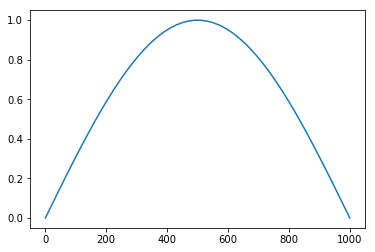

In [14]:
x = [x for x in np.linspace(0,1000)]

f = func_V3(x)

plt.plot(x, f)

#plt.xlim(0,50)
#plt.ylim(-0.2,1)

plt.show()

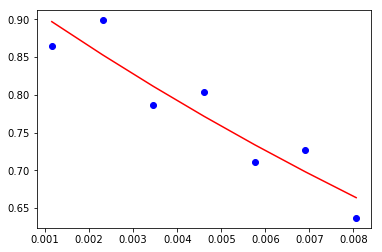

In [15]:
def func_V3(t, a, b, c):
    return np.array(np.absolute(a*np.exp(-t*b)*np.exp(2.0*np.pi*1j*c*t)))

popt, pcov = curve_fit(lambda t,a,b,c: np.absolute(a*np.exp(-t*b)*np.exp(2.0*np.pi*1j*c*t)),  t,  Sfinal)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(t, func_V3(t,*popt), 'r-', label='fit')
#plt.legend(handles=[p1, p2])

plt.show()

In [16]:
popt

array([  9.42980858e-01,   4.35628825e+01,  -3.41228062e+08])

In [17]:
#a = 1
#b = 0.8
#c = 1.3*3*42.58
#t = np.linspace(0,0.010,1000)
#y = np.array(np.absolute(a*np.exp(-t*b)*np.exp(2.0*np.pi*1j*c*t)))
#y2 = np.array(np.absolute(a*np.exp(-t/b)*np.exp(2.0*np.pi*1j*c*t)))
#plt.plot(t,y,t,y2)
plt.show()

C:\Users\Yuri\Anaconda2\lib\site-packages\numpy\core\numeric.py:482: ComplexWarning: Casting complex values to real discards the imaginary part
  return array(a, dtype, copy=False, order=order)


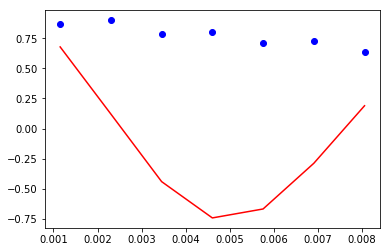

In [18]:
def func_V4(t, a, b, c):
    return np.array((a*np.exp(-t*b)*np.exp(2.0*np.pi*1j*c*t)))

popt, pcov = curve_fit(lambda t,a,b,c: np.absolute(a*np.exp(-t*b)*np.exp(2.0*np.pi*1j*c*t)),  t,  Sfinal)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(t, func_V4(t,*popt), 'r-', label='fit')
#plt.legend(handles=[p1, p2])

plt.show()

In [19]:
popt

array([  9.42980858e-01,   4.35628825e+01,  -3.41228062e+08])

In [20]:
1.3*3*42.58


166.062

In [21]:
import numpy as np
import matplotlib.pyplot as plt

TE = np.linspace(0,0.010,1001)
magField = 3.0 #Tesla
hydroGyro = 42.57e6 #Hz/T

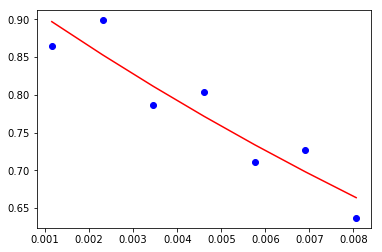

In [22]:
def func_V5(x, a, b, c, d, e, f):
    return np.abs(a*np.exp(b*x)*np.exp(c*x*2*np.pi) + d*np.exp(e*x)*np.exp(2.*np.pi*f/1e6*x))

popt, pcov = curve_fit(lambda t,a,b,c,d,e,f: np.abs(a*np.exp(b*t)*np.exp(c*t*2*np.pi) + d*np.exp(e*t)*np.exp(2.*np.pi*f/1e6*t)),  t,  Sfinal)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(t, func_V5(t,*popt), 'r-', label='fit')
plt.show()

In [23]:
popt

array([  6.10760606e-01,  -2.42455390e+01,  -3.07463431e+00,
         3.32220551e-01,   7.28052322e+01,  -1.85202574e+07])

In [24]:
x = np.linspace(0,0.01,1001)
y = np.abs(6.08023410e-01*np.exp(-2.42410661e+01*x)*np.exp(-3.07453864e+00*x*2*np.pi) + 3.34957373e-01*np.exp(7.28009431e+01*x)*np.exp(2.*np.pi*-1.85210020e+07/1e6*x))


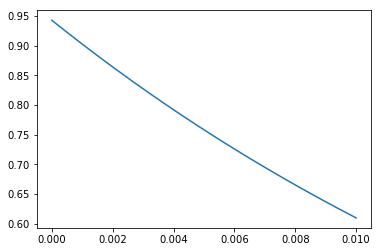

In [25]:
plt.plot(x,y)
plt.show()

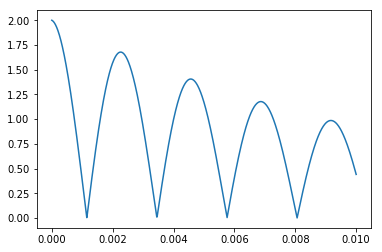

array([  6.10760606e-01,  -2.42455390e+01,  -3.07463431e+00,
         3.32220551e-01,   7.28052322e+01,  -1.85202574e+07])

In [26]:
y = np.abs(np.exp(-x/0.013)*np.exp(2.*np.pi*1j*1.3*magField*hydroGyro/1e6*x) + np.exp(-x/0.013)*np.exp(2.*np.pi*1j*4.7*magField*hydroGyro/1e6*x))

plt.plot(x,y)
plt.show()
popt

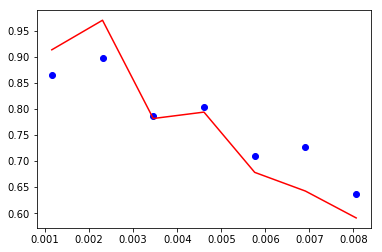

In [27]:
def func_V6(x, a, c, d, f):
    return np.absolute(a*np.exp(-x/0.013)*np.exp(2.*np.pi*1j*1.3*magField*hydroGyro/1e6*c*x) + 
                       d*np.exp(-x/0.013)*np.exp(2.*np.pi*1j*4.7*magField*hydroGyro/1e6*f*x))

popt, pcov = curve_fit(lambda t,a,c,d,f: np.absolute(a*np.exp(-t/0.013)*np.exp(2.*np.pi*1j*1.3*magField*hydroGyro/1e6*c*t) + 
                                                     d*np.exp(-t/0.013)*np.exp(2.*np.pi*1j*4.7*magField*hydroGyro/1e6*f*t)),  t,  Sfinal)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(t, func_V6(t,*popt), 'r-', label='fit')
plt.show()

In [28]:
popt

array([ 0.08630043, -3.38331969,  1.08178084, -0.2691814 ])

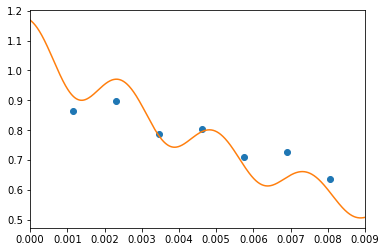

In [29]:
plt.plot(t, Sfinal, 'o')
plt.plot(x, func_V6(x,*popt))
plt.xlim(0,0.009)
#plt.ylim(0.5,0.95)
plt.show()


C:\Users\Yuri\Anaconda2\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


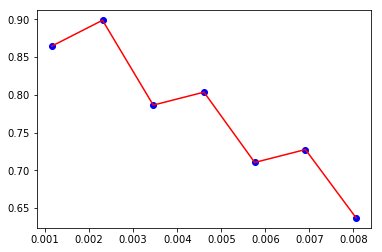

In [30]:
def func_V7(x, a,b,c,d,e,f,g):
    return np.absolute(a*np.exp(-x/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*x) + 
                       b*np.exp(-x/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*x) + 
                       c*np.exp(-x/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*x) + 
                       d*np.exp(-x/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*x) + 
                       e*np.exp(-x/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*x) +
                       f*np.exp(-x/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*x) +
                       g*np.exp(-x/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*x))

bd = (0, [1., 1., 1., 1., 1., 1., 1.]) # Bounds
popt, pcov = curve_fit(lambda t,a,b,c,d,e,f,g: np.absolute(a*np.exp(-t/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*t)+ 
                                                         b*np.exp(-t/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*t)+ 
                                                         c*np.exp(-t/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*t)+ 
                                                         d*np.exp(-t/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*t)+ 
                                                         e*np.exp(-t/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*t)+
                                                         f*np.exp(-t/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*t)+
                                                         g*np.exp(-t/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*t)),
                       t,  Sfinal, bounds=bd)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(t, func_V7(t,*popt), 'r-', label='fit2')
plt.show()

In [31]:
popt

array([ 0.33490454,  0.12562856,  0.51078796,  0.4887209 ,  0.28493101,
        0.6563741 ,  0.24721899])

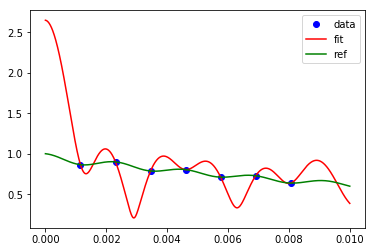

array([ 0.33490454,  0.12562856,  0.51078796,  0.4887209 ,  0.28493101,
        0.6563741 ,  0.24721899])

In [32]:
#rho = [fatPercent*0.047,\
#      fatPercent*0.039,\
#      fatPercent*0.006,\
#      fatPercent*0.12,\
#      fatPercent*0.7,\
#      fatPercent*0.088,\
#      1-fatPercent] #water
#rho
x = np.linspace(0,0.01,1001)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(x, func_V7(x,*popt), 'r-', label='fit')
plt.plot(x, func_V7(x,0.00235,0.0019500000000000001,0.00030000000000000003,0.006,0.034999999999999996,0.0044,0.95), 'g-', label='ref')
plt.legend()
plt.show()
popt

In [33]:
from scipy.stats import chisquare


In [34]:
chisquare(popt,rho)


Power_divergenceResult(statistic=1061.3128921727964, pvalue=4.8872818641293703e-226)

In [35]:
def func_V8(x, a, b, c, d, e, f, g):
    return np.absolute(a*np.exp(-x/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*x) + 
                       b*np.exp(-x/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*x) + 
                       c*np.exp(-x/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*x) + 
                       d*np.exp(-x/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*x) + 
                       e*np.exp(-x/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*x) +
                       f*np.exp(-x/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*x) +
                       g*np.exp(-x/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*x))

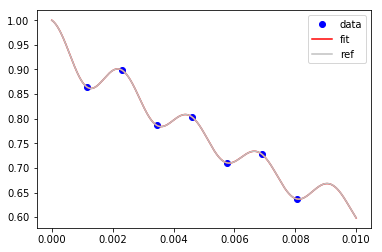

In [36]:
bd = (0, [1., 1., 1., 1., 1., 1., 1.]) # Bounds
popt, pcov = curve_fit(lambda t,a,b,c,d,e,f,g: np.absolute(a*np.exp(-t/0.030)*np.exp((2.*np.pi*1j*5.3*magField*hydroGyro/1e6)*t)+ 
                                                         b*np.exp(-t/0.040)*np.exp((2.*np.pi*1j*4.2*magField*hydroGyro/1e6)*t)+ 
                                                         c*np.exp(-t/0.051)*np.exp((2.*np.pi*1j*2.75*magField*hydroGyro/1e6)*t)+ 
                                                         d*np.exp(-t/0.052)*np.exp((2.*np.pi*1j*2.1*magField*hydroGyro/1e6)*t)+ 
                                                         e*np.exp(-t/0.062)*np.exp((2.*np.pi*1j*1.3*magField*hydroGyro/1e6)*t)+
                                                         f*np.exp(-t/0.083)*np.exp((2.*np.pi*1j*0.9*magField*hydroGyro/1e6)*t)+
                                                         g*np.exp(-t/0.023)*np.exp((2.*np.pi*1j*4.7*magField*hydroGyro/1e6)*t)),
                       t,  Sfinal, bounds=bd, p0=rho)
x = np.linspace(0,0.01,1001)
plt.plot(t,Sfinal,'bo',label='data')
plt.plot(x, func_V8(x,*popt), 'r-', label='fit')
plt.plot(x, func_V7(x,0.00235,0.0019500000000000001,0.00030000000000000003,0.006,0.034999999999999996,0.0044,0.95), '#C0C0C0', label='ref')
plt.legend(loc='best')
plt.show()

In [37]:
popt

array([  2.21584851e-03,   2.09457940e-03,   2.96094841e-04,
         6.02928652e-03,   3.49321680e-02,   4.43819584e-03,
         9.49985842e-01])

In [38]:
rho

array([  2.35000000e-03,   1.95000000e-03,   3.00000000e-04,
         6.00000000e-03,   3.50000000e-02,   4.40000000e-03,
         9.50000000e-01])

In [39]:
popt == rho


array([False, False, False, False, False, False, False], dtype=bool)

In [40]:
print('Diferença entre os parâmetros do fit com os valores reais:')
print(np.abs(popt-rho))

Diferença entre os parâmetros do fit com os valores reais:
[  1.34151486e-04   1.44579397e-04   3.90515942e-06   2.92865173e-05
   6.78319739e-05   3.81958385e-05   1.41583772e-05]
